# Phase 2 — General spatial heat sources

**Numerical Solution and PDE-Constrained Optimization of the Two-Dimensional Heat Equation**

This notebook extends the validated FTCS heat solver to accept arbitrary finite time-independent spatial source arrays or callables. It uses homogeneous initial/Dirichlet boundary conditions on the unit square.

## Mathematical model

$$
\begin{aligned}
\frac{\partial u}{\partial t}-\alpha\Delta u &= f(x,y), &&(x,y)\in(0,1)^2,\quad 0<t\le T,\\
u(x,y,0)&=0, &&(x,y)\in(0,1)^2,\\
u(x,y,t)&=0, &&(x,y)\in\partial\Omega.
\end{aligned}
$$

Define $h_x=1/N_x$, $h_y=1/N_y$, $r_x=\alpha\Delta t/h_x^2$, $r_y=\alpha\Delta t/h_y^2$. The explicit FTCS update is

$$
\begin{aligned}
u_{i,j}^{n+1}={}&u_{i,j}^n+r_x(u_{i+1,j}^n-2u_{i,j}^n+u_{i-1,j}^n)\\
&+r_y(u_{i,j+1}^n-2u_{i,j}^n+u_{i,j-1}^n)+\Delta t\,f_{i,j}.
\end{aligned}
$$

The sufficient standard timestep restriction is $r_x+r_y\le 1/2$. The solver chooses the number of time steps so that it reaches $T$ exactly without exceeding the safety fraction of the stability limit.

In [1]:
import numpy as np
from math import ceil
from dataclasses import dataclass

@dataclass
class HeatResult:
    x: np.ndarray
    y: np.ndarray
    source: np.ndarray
    final_temperature: np.ndarray
    dt: float
    nt: int
    stability_sum: float
    snapshots: dict


def gaussian_source(X, Y, amplitude=1.0, center=(0.5, 0.5), sigma=0.12):
    if sigma <= 0:
        raise ValueError("sigma must be positive")
    a, b = center
    return amplitude * np.exp(-((X-a)**2+(Y-b)**2)/(2*sigma**2))


def solve_heat_2d(source, nx=48, ny=48, alpha=0.1, T=0.1,
                  stability_fraction=0.9, snapshot_fractions=(0., 0.25, 0.5, 1.)):
    """Explicit FTCS on [0,1]^2 with zero initial and Dirichlet boundary data.

    source: callable f(X,Y) or ndarray with shape (nx+1, ny+1).
    Spatial source is assumed constant in time. Returns U[i,j] indexed by x,y.
    """
    if nx < 2 or ny < 2 or int(nx)!=nx or int(ny)!=ny:
        raise ValueError("nx and ny must be integers >= 2")
    if alpha <= 0 or T <= 0 or not (0 < stability_fraction <= 1):
        raise ValueError("Require alpha>0, T>0 and 0<stability_fraction<=1")
    hx, hy = 1.0/nx, 1.0/ny
    x, y = np.linspace(0, 1, nx+1), np.linspace(0, 1, ny+1)
    X, Y = np.meshgrid(x, y, indexing='ij')
    F = np.asarray(source(X,Y) if callable(source) else source, dtype=float)
    if F.shape != X.shape or not np.all(np.isfinite(F)):
        raise ValueError(f"source must have finite shape {(nx+1, ny+1)}")
    dt_max = 0.5/(alpha*(1/hx**2+1/hy**2))
    nt = max(1, ceil(T/(stability_fraction*dt_max)))
    dt = T/nt  # reaches final time exactly
    rx, ry = alpha*dt/hx**2, alpha*dt/hy**2
    assert rx+ry <= 0.5+1e-12
    U = np.zeros_like(F)
    wanted = {int(round(frac*nt)) for frac in snapshot_fractions}
    if any(not (0<=f<=1) for f in snapshot_fractions):
        raise ValueError("snapshot fractions must lie between 0 and 1")
    snapshots = {0: U.copy()} if 0 in wanted else {}
    for n in range(nt):
        V = np.zeros_like(U)
        V[1:-1,1:-1] = (
            U[1:-1,1:-1]
            + rx*(U[2:,1:-1]-2*U[1:-1,1:-1]+U[:-2,1:-1])
            + ry*(U[1:-1,2:]-2*U[1:-1,1:-1]+U[1:-1,:-2])
            + dt*F[1:-1,1:-1]
        )
        U = V
        if n+1 in wanted:
            snapshots[n+1] = U.copy()
    return HeatResult(x,y,F,U,dt,nt,rx+ry,snapshots)


## 1. Define candidate spatial sources

We test a sinusoidal verification source, an off-centre Gaussian, and a sum of two Gaussians. The source is **given**, not estimated, at this stage.

In [2]:
alpha, T = 0.1, 0.1
sinusoidal = lambda X,Y: np.sin(np.pi*X)*np.sin(np.pi*Y)
g1 = lambda X,Y: gaussian_source(X,Y,amplitude=1.0,center=(0.33,0.64),sigma=0.09)
g2 = lambda X,Y: gaussian_source(X,Y,amplitude=0.75,center=(0.72,0.38),sigma=0.12)
sources = {"Sinusoidal":sinusoidal,"Single Gaussian":g1,
           "Two Gaussians":lambda X,Y:g1(X,Y)+g2(X,Y)}
results = {label:solve_heat_2d(f,nx=48,ny=48,alpha=alpha,T=T)
           for label,f in sources.items()}
for label,r in results.items():
    print(f"{label}: steps={r.nt}, dt={r.dt:.8f}, r_x+r_y={r.stability_sum:.5f}, max T={r.final_temperature.max():.6f}")

Sinusoidal: steps=103, dt=0.00097087, r_x+r_y=0.44738, max T=0.090831
Single Gaussian: steps=103, dt=0.00097087, r_x+r_y=0.44738, max T=0.050533
Two Gaussians: steps=103, dt=0.00097087, r_x+r_y=0.44738, max T=0.051068


## 2. Visualize the source and the resulting temperature

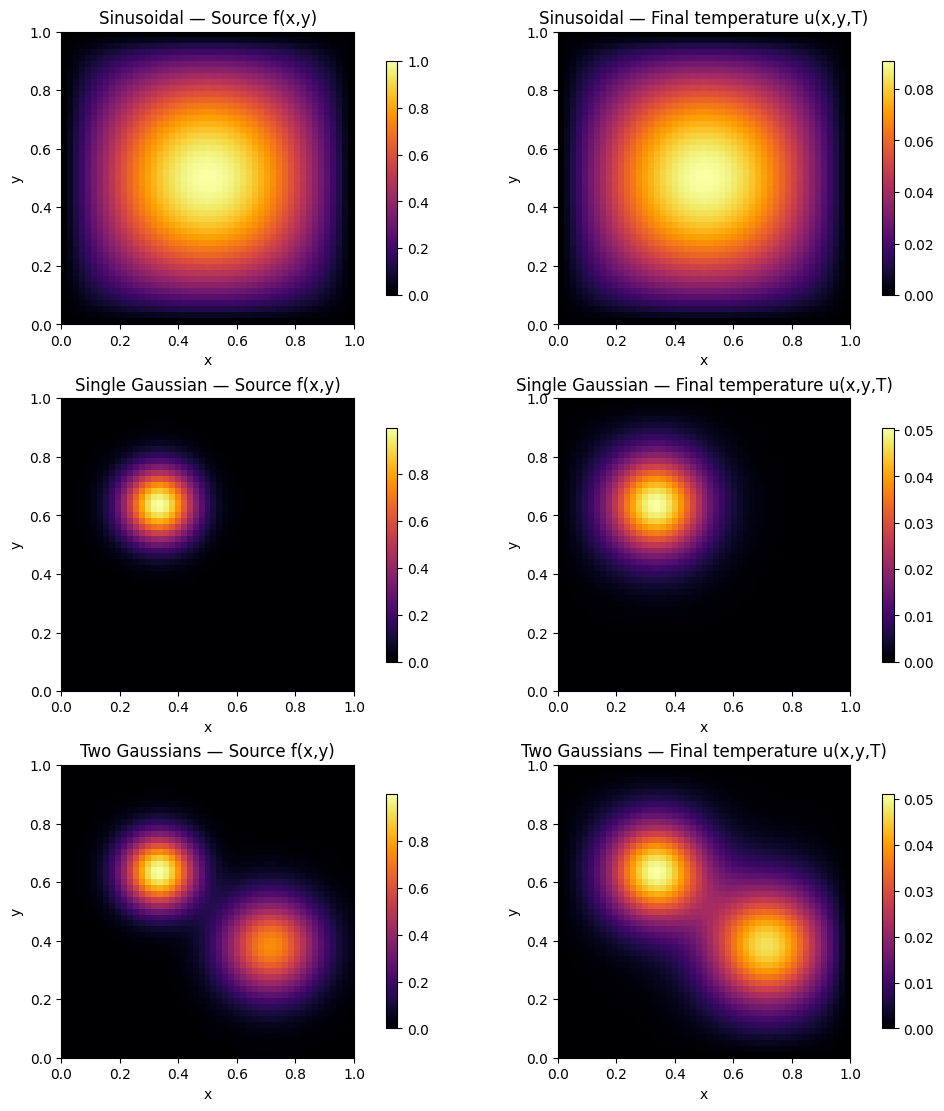

In [3]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3,2,figsize=(10,11),layout="constrained")
for row,(label,r) in enumerate(results.items()):
    for col,(Z,kind) in enumerate([(r.source,"Source f(x,y)"),
                                   (r.final_temperature,"Final temperature u(x,y,T)")]):
        im=axes[row,col].imshow(Z.T,origin="lower",extent=(0,1,0,1),cmap="inferno")
        axes[row,col].set(title=f"{label} — {kind}",xlabel="x",ylabel="y")
        fig.colorbar(im,ax=axes[row,col],shrink=.8)
plt.show()

## 3. Validate the sinusoidal case

For $f(x,y)=\sin(\pi x)\sin(\pi y)$, the exact solution is

$$u(x,y,t)=\frac{1-e^{-2\alpha\pi^2t}}{2\alpha\pi^2}\sin(\pi x)\sin(\pi y).$$

We compute the relative discrete spatial $L^2$ error at $t=T$ (equal to the ordinary vector-norm ratio on a uniform mesh).

## 4. Validate linear superposition

Because the PDE is linear and the initial and boundary conditions are zero, the forward solution operator satisfies:

$$
S(c_1 f_1 + c_2 f_2) = c_1 S(f_1) + c_2 S(f_2)
$$

Here, $S$ denotes the forward solution operator mapping a spatial heat source to its resulting temperature field. We verify that the numerical method satisfies this property to floating-point precision.

In [5]:
r1=solve_heat_2d(g1,nx=32,ny=32)
r2=solve_heat_2d(g2,nx=32,ny=32)
r12=solve_heat_2d(lambda X,Y:1.3*g1(X,Y)-0.4*g2(X,Y),nx=32,ny=32)
superposition_error=np.max(np.abs(r12.final_temperature-(1.3*r1.final_temperature-0.4*r2.final_temperature)))
print(f"max superposition discrepancy = {superposition_error:.3e}")
assert superposition_error<1e-13

max superposition discrepancy = 2.082e-17


## 5. Check boundary conditions and zero-source behaviour

In [6]:
r0=solve_heat_2d(lambda X,Y:np.zeros_like(X),nx=16,ny=16)
assert np.array_equal(r0.final_temperature,np.zeros_like(r0.final_temperature))
for label,r in results.items():
    U=r.final_temperature
    assert np.all(U[0,:]==0) and np.all(U[-1,:]==0)
    assert np.all(U[:,0]==0) and np.all(U[:,-1]==0)
print("All checks passed: zero source, zero boundaries, stability, analytical benchmark and superposition.")

All checks passed: zero source, zero boundaries, stability, analytical benchmark and superposition.



## 6. Prepare for the inverse problem

Let the unknown source be parametrized by basis functions:

$$
f_{\theta}(x,y) = \sum_{r=1}^{p} \theta_r \phi_r(x,y)
$$

Because the solver is linear, each basis function can be solved once to obtain its temperature response.

In the next phase, we will select observation points and times, define a measurement operator H, and form the observation model:

$$
\mathbf{d} \approx A\boldsymbol{\theta} + \boldsymbol{\varepsilon}
$$

The entries of the observation-response matrix are:

$$
A_{kr} = H_k(u_r)
$$

Here, H represents the observation operator, and u_r is the temperature field generated by the r-th source basis function.

At that point, we can reconstruct the unknown coefficients using regularized least squares.

**No inverse reconstruction or optimization has yet been performed in this notebook.**

### Limitations

- Only time-independent, finite spatial sources on the chosen grid are supported.
- Initial and Dirichlet boundary conditions are fixed at zero.
- FTCS is conditionally stable.
- Sensor extraction and regularized optimization are deferred to Notebook
